# EE191 Exercise - Support Vector Machines

In this exercise, we will introduce a typical machine learning training pipeline using 10-fold cross-validation.

The dataset labeled "train" in the Excel file represents the data we have available (e.g., collected from a project or retrieved from a database). In contrast, the sheet labeled "test" simulates completely unseen data that the model has not yet encountered.

During training, the process optimizes model parameters, but it does not tune hyperparameters. Hyperparameter tuning requires a separate validation set to evaluate candidate hyperparameters without introducing bias. In practice, the validation set is usually created by partitioning the training data. For example, in 10-fold cross-validation, one fold is designated as the validation set (used for hyperparameter optimization), while the remaining folds are used for training the model parameters.

After partitioning the dataset, we can train multiple models and evaluate their performance on the validation set to identify a suitable (sub-optimal) set of hyperparameters. This process is known as hyperparameter optimization!

In this exercise, we will explore three (3) widely used hyperparameter tuning methods:

1. Grid Search – exhaustively searches over a predefined set of hyperparameter values.

2. Random Search – samples hyperparameters randomly within a given range.

3. Bayesian Optimization – uses past evaluations to intelligently select promising hyperparameters.

The provided code is kept intentionally simple to focus on the core concepts of each code blocks. Feel free to extend and adapt this for in your personal projects in the future!

# Loading Libraries

Before proceeding with the exercise, we first load the libraries that will be used throughout this notebook. Libraries are collections of pre-written code that provide useful functions and tools for specific tasks, such as data processing, visualization, and machine learning. By using libraries, we can focus on solving the problem at hand without needing to implement every component from scratch!

In [270]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from sklearn.svm import SVC

# Loading the Dataset

First, we load our training set.

In [271]:
def load_data(file_path, sheet_number):
    '''
    This function loads the sample features and labels from a dataset.
    
    INPUT:
        file_path - Path to the dataset file.
        sheet_number - Name or index of the sheet to load (e.g., training or test set).
    
    OUTPUT:
        X (float64) - Feature matrix of the dataset. An N × m matrix, where N is the number of samples and m is the number of features.
        y (categorical) - Label vector. An N × 1 array containing the class label corresponding to each sample.
    '''
    
    # Read the sheet as a dataframe
    df = pd.read_excel(file_path, sheet_name=sheet_number); 
    
    # Split the loaded dataframe into feature and label based on the column number
    y = df.iloc[:, 0];      # label --> first col
    X = df.iloc[:, 1:3];    # feature --> 2nd col and so on
    
    # Convert to numericals to avoid possible NaN errors.
    y = y.values;
    X = X.values;

    # Print a dataset summarry.
    print(f"Dataset successfully loaded. {len(y[y==1])} class 1 samples and {len(y[y==0])} class 0 samples loaded.");

    return X, y;

In [272]:
# Load dataset
X_train, y_train = load_data("dataset.xlsx","train");

Dataset successfully loaded. 181 class 1 samples and 179 class 0 samples loaded.


## Data Visualization

Prior to model training, it is often helpful to visualize the sample distribution to identify potential patterns or structures in the data. In classification problems, the degree of overlap between class distributions can provide insight into the type of model that may be appropriate.

In general, datasets with larger overlaps between classes tend to require more complex models to capture nonlinear decision boundaries. Conversely, datasets with minimal overlap can often be handled effectively by simpler models. For example, when the data are linearly separable, high-parameter models, such as polynomial models, are typically unnecessary.

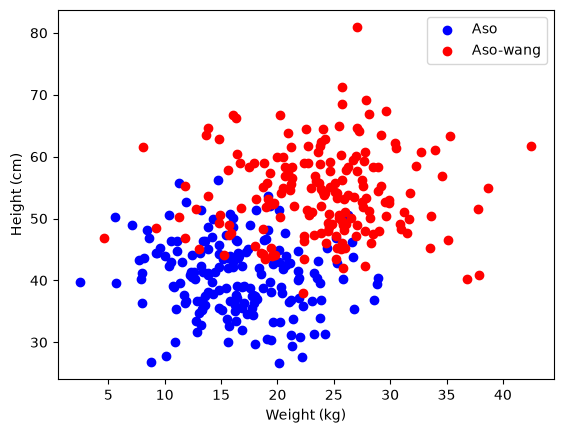

In [273]:
# Configure figure space
plt.figure()

# Plot class 0 in blue
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
            color='blue', label='Aso')

# Plot class 1 in red
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
            color='red', label='Aso-wang')

# Insert axis labels
plt.xlabel("Weight (kg)")
plt.ylabel("Height (cm)")
plt.legend()

plt.show()

As shown in the figure above, the overlap between the classes is neither large nor negligible. This suggests that the features used in this dataset were appropriately selected for the task of discriminating between the classes. If the features had little to no relationship with class separability, the distributions would likely appear heavily overlapped or fully intersecting, making meaningful classification much more difficult.

## Model Training

Before tuning the model’s hyperparameters, it is helpful to first understand how the training process is typically carried out in practical machine learning projects. In this exercise, we will implement a 10-fold cross-validation procedure.

In this method, the dataset is first partitioned into 10 equally sized subsets (folds). Each fold should maintain similar class proportions, and the samples within each fold should be randomly selected. This approach is known as stratified sampling. The function below performs this stratification and partitioning.

After partitioning the dataset, we will train a Support Vector Machine (SVM) model using the Scikit-learn's library. In most real-world machine learning projects, practitioners rely on well-established libraries rather than implementing models from scratch. While building models from scratch can be a valuable learning experience, it often requires significant time and effort. Since the primary goal of this exercise is to familiarize you with the typical machine learning workflow, we avoid introducing unnecessary implementation complexities.

In practice, having a solid understanding of how the model works and how each hyperparameter affects its behavior is usually sufficient for effectively applying these tools! --- that's what our lectures were for.

In [274]:
def stratified_kfold(y, num_folds=10, random_seed=42):
    '''
    This function stratifies a dataset into k folds.
    
    INPUT:
        y (categorical) - Label vector. An N × 1 array containing the class label corresponding to each sample.
        num_folds (int) - Number of stratified partitions (folds).
        random_seed (int) - Random seed used for reproducibility. This ensures consistent results and enables fair model comparison.
    
    OUTPUT:
        n_folds (list of int lists) - A list containing k integer vectors. Each vector stores the indices of the samples belonging to the corresponding fold.
    
    '''

    # initializing random seed
    random.seed(random_seed)

    # Separate indices by class. This helps during the stratification.
    class_indices = {}
    for i, label in enumerate(y):
        if label not in class_indices:
            class_indices[label] = []
        class_indices[label].append(i)

    # Shuffle indices in each class to randomize.
    for label in class_indices:
        random.shuffle(class_indices[label])

    # Create empty folds to store the fold sample indeces.
    n_folds = [[] for _ in range(num_folds)]

    # Distribute indices across folds
    for label in class_indices:
        indices = class_indices[label]
        for i, idx in enumerate(indices):
            fold_id = i % num_folds
            n_folds[fold_id].append(idx)

    # Print fold sizes for reporting
    for i, n_fold in enumerate(n_folds):
        print(f"Fold {i+1}: {len(n_fold)} samples");

    return n_folds

In [275]:
# Generate folds
n_folds = stratified_kfold(y_train, num_folds=10)

Fold 1: 37 samples
Fold 2: 36 samples
Fold 3: 36 samples
Fold 4: 36 samples
Fold 5: 36 samples
Fold 6: 36 samples
Fold 7: 36 samples
Fold 8: 36 samples
Fold 9: 36 samples
Fold 10: 35 samples


In hyperparameter optimization, one fold is used as the validation set, while the remaining folds are used for training. Since there are a total of 10 folds, the training and evaluation process is repeated 10 times, each time designating a different fold as the validation set and using the remaining folds for training.

It is important to note that the folds do not share any samples with one another; they are mutually exclusive. This property is essential for ensuring proper training practices and helps prevent issues such as data leakage and data snooping, which can lead to overly optimistic performance estimates.

In the code below, we visualize the training set and validation set for each fold being considered. Feel free to modify the "selected_fold" variable in order to look into different fold partitions!

In [276]:
# Fold you want to visualize
selected_fold = 0

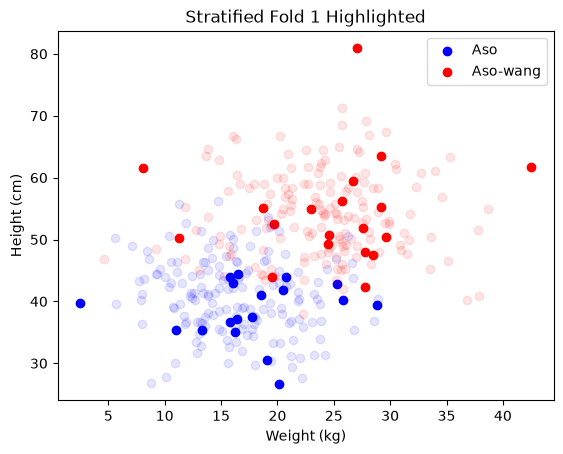

In [277]:
# Initialize figure space
plt.figure()

# Selected indices acts as those from the validation set.
selected_indices = set(n_folds[selected_fold])

for i in range(len(X_train)):
    x = X_train[i, 0]
    y = X_train[i, 1]
    label = y_train[i]

    # Validation set data are drawn in bolder color; while training data are lighter
    if i in selected_indices:
        alpha = 1.0   # strong color
    else:
        alpha = 0.1   # lighter color

    if label == 0:
        plt.scatter(x, y, color='blue', alpha=alpha) # for class 0 samples
    else:
        plt.scatter(x, y, color='red', alpha=alpha) # for class 1 samples

plt.xlabel("Weight (kg)")
plt.ylabel("Height (cm)")

# Plotting labels and legends
plt.scatter([], [], color='blue', label='Aso')
plt.scatter([], [], color='red', label='Aso-wang')
plt.legend()
plt.title(f"Stratified Fold {selected_fold+1} Highlighted")

plt.show()

In the figure, the dark-colored points correspond to samples belonging to the validation set.

# 1. Training a Single Model

With everything set up, we can now proceed to train an SVM model to fit our dataset. In this exercise, we will train a Support Vector Machine using a Gaussian kernel, referred to in the implementation as "rbf" (Radial Basis Function).

Recall that this model has two key hyperparameters. The first is the SVM regularization constant, denoted by C, which controls the trade-off between maximizing the margin and minimizing classification errors. The second hyperparameter is associated with the kernel itself: the standard deviation of the Gaussian function. In the Scikit-learn library, this parameter is referred to as gamma.

In this part of the exercise, the model is trained 10 times, each time using a different fold as the validation set while the remaining folds are used for training. This repeated training helps improve statistical reliability. The overall performance of the model is then computed as the average accuracy across the validation sets of all folds. In practice, we should also report the standard deviation; here, we omit it for simplicity.

To build intuition about how SVMs behave, you are encouraged to experiment with different hyperparameter combinations and observe how the decision boundary changes. Doing so will help you develop a deeper understanding of how the model responds to different settings.


**Loading SVM-related Helper Functions**

Helper functions refer to functions that support the implementation of a given algorithm. In this step, we load the helper functions used for training and evaluating SVM models. This only needs to be executed once, as these functions will be used repeatedly throughout the exercise. Although the code has already been provided, you are encouraged to review the documentation to see how these functions are implemented. This can be helpful if you need to create similar functions in the future!

In [278]:
def create_n_fold_dataset(X, y, n_folds, val_fold):
    '''
    This function returns the training and validation sets using a selected fold as the validation set.
    
    INPUTS:
        X (float64) - Feature matrix of the dataset. An N × m matrix, where N is the number of samples and m is the number of features.
        y (categorical) - Label vector. An N × 1 array containing the class label corresponding to each sample.
        n_folds (list of int lists) - A list containing k integer vectors. Each vector stores the indices of the samples belonging to the corresponding fold.
        val_fold (int) - Index of the fold to be used as the validation set.
    
    OUTPUT:
        X_tr (float64) - Feature matrix of the training set. An N × m matrix containing the training samples.
        X_val (float64) - Feature matrix of the validation set. An N × m matrix containing the validation samples.
        y_tr (categorical) - Label vector of the training set. An N × 1 array containing the class labels for the training samples.
        y_val (categorical) - Label vector of the validation set. An N × 1 array containing the class labels for the validation samples.
    
    '''
    # Validation indices
    val_idx = n_folds[val_fold]
    
    # Training indices (all other folds)
    train_idx = []
    for i, fold in enumerate(n_folds):
        if i != val_fold:
            train_idx.extend(fold)
    
    # Build datasets
    X_tr = X_train[train_idx]
    y_tr = y_train[train_idx]
    
    X_val = X_train[val_idx]
    y_val = y_train[val_idx]

    return X_tr, X_val, y_tr, y_val;

def train_SVM(C, gamma, X_tr, y_tr):
    '''
    This function trains a Support Vector Machine (SVM) model using a Gaussian (RBF) kernel.

    INPUT:
        C (float64) - SVM regularization constant.
        gamma (fload64) - gaussian kernel spread.
        X_tr (float64) - Feature matrix of the training set. An N × m matrix containing the training samples.
        y_tr (categorical) - Label vector of the training set. An N × 1 array containing the class labels for the training samples.
    
    OUTPUT:
        model (object) - trained SVM model 
    '''
    # Train SVM with RBF kernel
    model = SVC(kernel='rbf',C= C, gamma=gamma)
    model.fit(X_tr, y_tr)

    return model;

def evaluate_SVM(model, X_val, y_val):
    '''
    This function evaluates the performance of a trained model by computing its accuracy on the validation dataset {X_val, y_val}

    INPUTS:
        model (object) - trained SVM model 
        X_val (float64) - Feature matrix of the validation set. An N × m matrix containing the validation samples.
        y_val (categorical) - Label vector of the validation set. An N × 1 array containing the class labels for the validation samples.

    OUTPUT:
        accuracy (float64) - trained model accuracy
    '''

    # Get prediction probabilities
    y_pred = model.predict(X_val)

    # Compute for accuracy
    correct = 0;
    for i in range(len(y_val)):
        if y_pred[i] == y_val[i]:
            correct += 1
    
    accuracy = correct / len(y_val)
    
    return accuracy;
    
def visualize_boundary(model, X, y):
    '''
    This function visualizes the decision boundary of a trained model based on its training data.
    
    INPUTS:
        model (object) - trained SVM model 
        X (float64) - Feature matrix of the dataset. An N × m matrix, where N is the number of samples and m is the number of features.
        y (categorical) - Label vector. An N × 1 array containing the class label corresponding to each sample.

    OUTPUT:
        boundary visualization
    '''
    # Create grid for decision boundary
    x_min, x_max = X[:,0].min() - 1, X[:,0].max() + 1
    y_min, y_max = X[:,1].min() - 1, X[:,1].max() + 1
    
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    # Evaluate the points within the grid
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid_points)
    Z = Z.reshape(xx.shape)
    
    plt.figure()
    
    # Draw decision boundary where the probability is 50-50
    plt.contour(xx, yy, Z, levels=[0.5], colors='black')

    # Plotting the samples...
    # Plot class 0 in blue
    plt.scatter(X_train[y_train == 0, 0], X[y == 0, 1],
                color='blue', label='Aso')
    
    # Plot class 1 in red
    plt.scatter(X_train[y_train == 1, 0], X[y == 1, 1],
                color='red', label='Aso-wang')
    
    plt.xlabel("Weight (kg)")
    plt.ylabel("Height (cm)")
    plt.legend()
    
    plt.show()
    
print("Helper functions initialized...")

Helper functions initialized...


**Training Proper**

Try different hyperparameters!

Validation accuracy: 0.8378


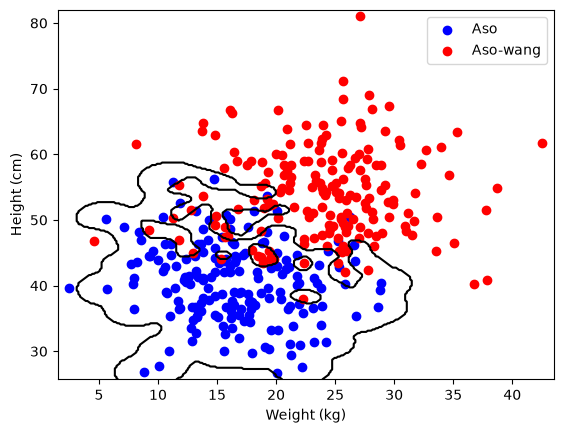

In [279]:
# Selected fold as validation set
val_fold = 0;

# SVM hyperparameters
C = 20;
gamma = 0.5;

# Training and Evaluation
X_tr, X_val, y_tr, y_val = create_n_fold_dataset(X_train, y_train, n_folds, val_fold);
model = train_SVM(C, gamma, X_tr, y_tr);
acc = evaluate_SVM(model, X_val, y_val);
print(f"Validation accuracy: {acc :.4f}")

# Visualization
visualize_boundary(model, X_train, y_train);

# Hyperparameter Optimization

Manually exploring the hyperparameter space is generally not a practical approach in machine learning. While it can help build some intuition about the scale of the search space, it often leads to uncertainty and inconsistency in the optimization process. For this reason, a systematic hyperparameter optimization strategy should always be used.

Hyperparameter tuning can be computationally expensive, so the search space must be carefully defined. Ideally, it should be large enough to contain satisfactory solutions, but small enough to allow efficient exploration. What constitutes a satisfactory result depends on the context and requirements of the problem. However, if the resulting performance metrics are consistently low, this may indicate several issues: the number of sampled hyperparameters may be insufficient, the search space may be poorly defined, or the chosen model or feature set may not be appropriate for the problem, among other possibilities.

In this exercise, we will explore three of the most widely used hyperparameter optimization methods. Most of the code has already been provided, but you will be asked to complete the remaining portions as part of the exercise.

**Loading Hyperparameter Optimization Helper Function**

In [280]:
import matplotlib.pyplot as plt

def plot_hyperparam_accuracy_map(C_record, gamma_record, acc_record):
    """
    This function visualizes the hyperparameter-performance landscape by plotting model performance as a color-coded graph against the hyperparameters.
    
    INPUTS:
        C_record (float64)   - An N × 1 array containing the C values explored during hyperparameter optimization.
        gamma_record (float64) - An N × 1 array containing the gamma values explored during hyperparameter optimization.
        acc_record (float64)   - An N × 1 array containing the accuracy corresponding to each hyperparameter combination of C and gamma.
    
        *Note: The indices of the _record variables correspond to each other.
    
    OUTPUTS:
        A visualization of the hyperparameter search space, showing how performance varies with different C and gamma values.
    """
    plt.figure(figsize=(8,6))

    # Use scatter with color mapped to accuracy
    scatter = plt.scatter(
        C_record,
        gamma_record,
        c=acc_record,          # color by accuracy
        cmap='viridis',        # colormap
        s=160,                  # marker size
    )

    plt.xscale('log')  # often better to use log scale for C
    plt.yscale('log')  # and gamma
    plt.xlabel("C")
    plt.ylabel("Gamma")
    
    # Add colorbar for accuracy magnitude
    cbar = plt.colorbar(scatter)
    cbar.set_label("Accuracy")

    plt.show()

## 2. Grid Search

In grid search, we systematically explore different hyperparameter combinations by defining discrete sets of values for each hyperparameter. The time complexity of grid search is generally the highest among hyperparameter tuning methods, as it grows exponentially with the number of discrete values per hyperparameter and the total number of hyperparameters considered.

Despite the high computational cost, grid search provides a comprehensive mapping of the search space, making it highly accurate. This method is often preferred when the goal is to understand model behavior and improve interpretability, rather than simply finding a sub-optimal solution quickly.

In [317]:

#==================YOUR=CODE=HERE==========================
# Initializing hyperparameter values to try. These are exponential arguments (E.g. 10^C_log10_vector[0])

C_log10_vector = [-4, -3, -2, -1, 0, 1, 2, 3, 4];
gamma_log10_vector = [-4, -3, -2, -1, 0, 1, 2, 3, 4];

#==========================================================

# Initializing holder variables for results
C_record = [];
gamma_record = [];
acc_record = [];

# For-LOOP for trying different hyperparameters
for C_log10_value in C_log10_vector:
    for gamma_log10_value in C_log10_vector:

        # list to store metrics from each fold
        acc_metrics = [];

        # initializing hyperparameters
        C = 10**C_log10_value;
        gamma = 10**gamma_log10_value;

        C_record.append(C);
        gamma_record.append(gamma);

        # For-LOOP for different folds
        for k in range(len(n_folds)): #n_folds(10)

            # create training-validation set for the kth fold
            X_tr, X_val, y_tr, y_val = create_n_fold_dataset(X_train, y_train, n_folds, k); #n_folds(10)

            #==================YOUR=CODE=HERE==========================
            
            # Train model
            model = train_SVM(C, gamma, X_tr, y_tr);

            # Evaluate model
            acc = evaluate_SVM(model, X_val, y_val);
            #==========================================================

            acc_metrics.append(acc);

        # average accuracies over multiple folds
        ave_acc = sum(acc_metrics)/len(n_folds);
        acc_record.append(ave_acc);

        print(f"C={C:.5f}; gamma={gamma:.5f}: --- Acc: {ave_acc:.4f}")

C=0.00010; gamma=0.00010: --- Acc: 0.5028
C=0.00010; gamma=0.00100: --- Acc: 0.5028
C=0.00010; gamma=0.01000: --- Acc: 0.5028
C=0.00010; gamma=0.10000: --- Acc: 0.5028
C=0.00010; gamma=1.00000: --- Acc: 0.5028
C=0.00010; gamma=10.00000: --- Acc: 0.5028
C=0.00010; gamma=100.00000: --- Acc: 0.5028
C=0.00010; gamma=1000.00000: --- Acc: 0.5028
C=0.00010; gamma=10000.00000: --- Acc: 0.5028
C=0.00100; gamma=0.00010: --- Acc: 0.5028
C=0.00100; gamma=0.00100: --- Acc: 0.5028
C=0.00100; gamma=0.01000: --- Acc: 0.5028
C=0.00100; gamma=0.10000: --- Acc: 0.5028
C=0.00100; gamma=1.00000: --- Acc: 0.5028
C=0.00100; gamma=10.00000: --- Acc: 0.5028
C=0.00100; gamma=100.00000: --- Acc: 0.5028
C=0.00100; gamma=1000.00000: --- Acc: 0.5028
C=0.00100; gamma=10000.00000: --- Acc: 0.5028
C=0.01000; gamma=0.00010: --- Acc: 0.5028
C=0.01000; gamma=0.00100: --- Acc: 0.6080
C=0.01000; gamma=0.01000: --- Acc: 0.8694
C=0.01000; gamma=0.10000: --- Acc: 0.5028
C=0.01000; gamma=1.00000: --- Acc: 0.5028
C=0.01000; gam

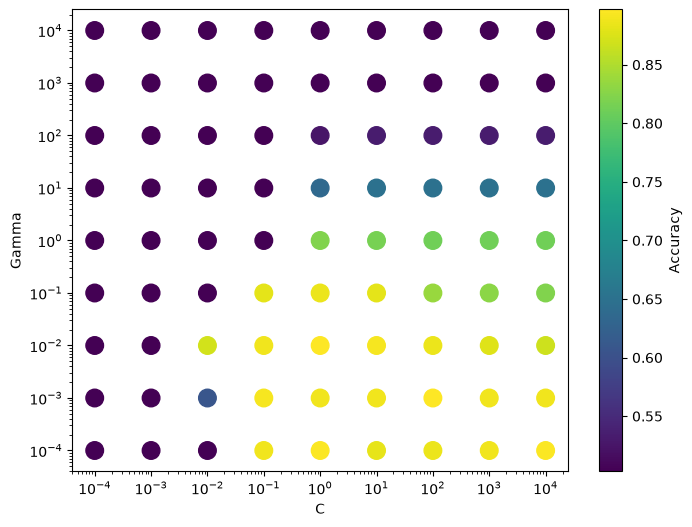

In [282]:
plot_hyperparam_accuracy_map(C_record, gamma_record, acc_record)

Each point represents a model trained with a particular hyperparameter configuration. The model’s performance is represented by color, as indicated by the color bar on the right.

## 3. Random Search

Instead of specifying discrete values, random search explores an entire subset of the hyperparameter domain. In this approach, bounds are defined for each hyperparameter, rather than selecting specific values. Hyperparameter combinations are then randomly sampled from these domains and evaluated accordingly.

The search continues either until a sufficiently good solution is found or until a predefined number of trials has been reached. The hyperparameter combination that achieves the highest performance metric is then selected as the sub-optimal solution.

In [328]:
import random
#==================YOUR=CODE=HERE==========================

# Initialize total number of random hyperparameter combinations to consider
n_samples = 81

#==========================================================

# Initializing holder variables for results
C_record = [];
gamma_record = [];
acc_record = [];

# For-LOOP for trying different hyperparameters
for i in range(n_samples):

    #==================YOUR=CODE=HERE==========================
    # Randomizing hyperparameter values.
    # Tip: random.uniform(a,b); generates a random real number from a to b
    
    C_log10_value = random.uniform(-4,4);
    
    gamma_log10_value = random.uniform(-4,4);

    #==========================================================
    
    # Initializing hyperparameters
    C = 10**C_log10_value;
    gamma = 10**gamma_log10_value;

    C_record.append(C);
    gamma_record.append(gamma);

    acc_metrics = []
    
    # For-LOOP for different folds
    for k in range(len(n_folds)):
        # create training-validation set for the kth fold
        X_tr, X_val, y_tr, y_val = create_n_fold_dataset(X_train, y_train, n_folds, k);

        #==================YOUR=CODE=HERE==========================
        
        # Train model
        model = train_SVM(C, gamma, X_tr, y_tr);

        # Evaluate model
        acc = evaluate_SVM(model, X_val, y_val);

        #==========================================================

        acc_metrics.append(acc)

    # average accuracies over multiple folds
    ave_acc = sum(acc_metrics) / len(acc_metrics);
    acc_record.append(ave_acc);

    print(f"C={C:.5f}; gamma={gamma:.5f}: --- Acc: {ave_acc:.4f}")

C=183.32932; gamma=161.91840: --- Acc: 0.5194
C=4.17903; gamma=59.04742: --- Acc: 0.5501
C=4.65786; gamma=0.00231: --- Acc: 0.8942
C=10.76966; gamma=9.07583: --- Acc: 0.6612
C=536.21258; gamma=0.00152: --- Acc: 0.8888
C=27.91356; gamma=0.00018: --- Acc: 0.8859
C=3851.60167; gamma=0.00076: --- Acc: 0.8861
C=0.00014; gamma=0.03233: --- Acc: 0.5028
C=0.00163; gamma=33.41966: --- Acc: 0.5028
C=0.19188; gamma=158.40848: --- Acc: 0.5028
C=2312.95721; gamma=960.59798: --- Acc: 0.5028
C=77.03679; gamma=0.00031: --- Acc: 0.8859
C=0.00127; gamma=0.00456: --- Acc: 0.5028
C=0.03985; gamma=19.85246: --- Acc: 0.5028
C=1.59888; gamma=0.03236: --- Acc: 0.8944
C=0.00243; gamma=1981.49640: --- Acc: 0.5028
C=0.05478; gamma=0.06828: --- Acc: 0.8805
C=149.94026; gamma=58.53242: --- Acc: 0.5501
C=14.01112; gamma=35.19707: --- Acc: 0.5723
C=7.59648; gamma=0.00345: --- Acc: 0.8916
C=0.00938; gamma=2.91537: --- Acc: 0.5028
C=0.00629; gamma=6071.34652: --- Acc: 0.5028
C=0.02404; gamma=0.02051: --- Acc: 0.8832
C

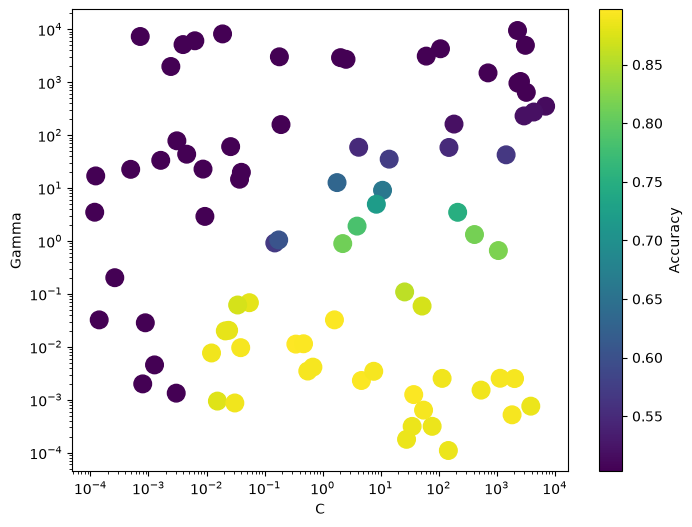

In [329]:
plot_hyperparam_accuracy_map(C_record, gamma_record, acc_record)

# 4. Bayesian Optimization

In Bayesian optimization the hyperparameter space is "intelligently" explored by using a probabilistic model to predict performance given prior hyperparameter combinations. The process begins with an initial phase of sampling, where a small number of hyperparameter combinations—called priors—are randomly evaluated to gather baseline performance data (i.e. random search!). These priors serve as the foundation for the probabilistic model, which estimates the relationship between hyperparameters and the objective metric; here the validation accuracy.

Once the initial priors are collected, subsequent points are selected systematically using an acquisition function, which balances exploration (sampling areas of the space with high uncertainty) and exploitation (sampling areas predicted to yield high performance). This allows the algorithm to focus evaluations on the most promising regions of the hyperparameter space, improving efficiency compared to random or grid search.

As new points are evaluated, the model is updated iteratively, incorporating the results into the probabilistic model to refine predictions. This process continues until a stopping criterion is met, such as a maximum number of iterations or achieving a sufficiently high performance metric.

The final hyperparameter combination is chosen as the one predicted to provide the best expected performance, making Bayesian Optimization particularly useful when evaluations are expensive and the search space is large or complex. Overall, this approach is sample-efficient and often finds better solutions faster than exhaustive or purely random search methods!

We will not be implementing the optimization procedure from scratch, as this is a complex topic in its own right. Instead, we provide the base code for this process. In my experience, Bayesian optimization is one of the most practical hyperparameter tuning techniques, being both widely accepted in academic research and robust enough for real-world applications. You are encouraged to familiarize yourself with how it is implemented in code, as understanding its workflow will help you apply it effectively in future projects!

In [324]:
from skopt import gp_minimize
from skopt.space import Real
import numpy as np

# Define search space
space  = [
    Real(-4, 4, name='C_log10'),
    Real(-4, 4, name='gamma_log10')
]

# Initializing holder variables for results
C_record = [];
gamma_record = [];

# Objective function: negative accuracy because gp_minimize minimizes not maximizes
def objective(params):
    C_log10, gamma_log10 = params
    C = 10**C_log10
    gamma = 10**gamma_log10

    acc_metrics = []

    for k in range(len(n_folds)):
        # create training-validation set for the kth fold
        X_tr, X_val, y_tr, y_val = create_n_fold_dataset(X_train, y_train, n_folds, k);

        #==================YOUR=CODE=HERE==========================
        
        # Train model
        model = train_SVM(C, gamma, X_tr, y_tr);

        # Evaluate model
        acc = evaluate_SVM(model, X_val, y_val);

        #==========================================================
        
        acc_metrics.append(acc)  # use accuracy for optimization

    ave_acc = sum(acc_metrics) / len(acc_metrics)

    print(f"C={C:.5f}; gamma={gamma:.5f}: --- Acc: {ave_acc:.4f}")

    # negative because gp_minimize tries to minimize not maximize
    return -ave_acc

# Run Bayesian optimization
res = gp_minimize(objective, space, n_calls=20, n_initial_points=10, random_state=42)

# Extract best parameters
C_record = [10**x[0] for x in res.x_iters]
gamma_record = [10**x[1] for x in res.x_iters]
acc_record = -res.func_vals;

C=235.69149; gamma=0.00293: --- Acc: 0.8916
C=172.79374; gamma=5.95390: --- Acc: 0.7000
C=0.36869; gamma=0.00063: --- Acc: 0.8860
C=0.47205; gamma=0.04674: --- Acc: 0.8944
C=0.00139; gamma=16.11045: --- Acc: 0.5028
C=0.00028; gamma=59.70218: --- Acc: 0.5028
C=3224.19776; gamma=0.00010: --- Acc: 0.8915
C=8663.48194; gamma=8.70667: --- Acc: 0.6612
C=7.82033; gamma=0.00011: --- Acc: 0.8859
C=0.00015; gamma=1.57833: --- Acc: 0.5028
C=3.07732; gamma=0.01039: --- Acc: 0.8916
C=0.00010; gamma=0.00010: --- Acc: 0.5028
C=262.13584; gamma=0.00010: --- Acc: 0.8886
C=1371.86272; gamma=0.00123: --- Acc: 0.8834
C=0.82042; gamma=0.00669: --- Acc: 0.8971
C=38.84678; gamma=0.00111: --- Acc: 0.8916
C=10000.00000; gamma=0.00010: --- Acc: 0.8944
C=1.31523; gamma=0.28341: --- Acc: 0.8778
C=1.13386; gamma=0.00010: --- Acc: 0.8942
C=1.90961; gamma=0.00068: --- Acc: 0.8859


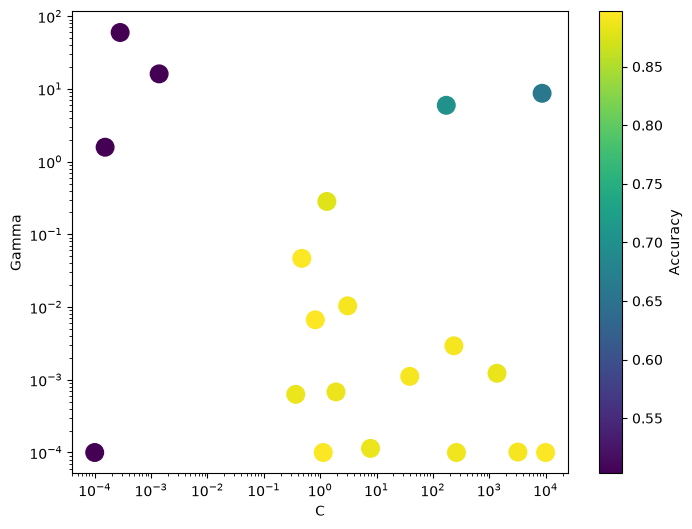

In [286]:
plot_hyperparam_accuracy_map(C_record, gamma_record, acc_record)

## 6. Model Testing

Now that we have optimized the hyperparameters, we can proceed to evaluate the test set. In this step, we retrain the model using the entirety of the first sheet, which previously served as both the training and validation data during cross-validation. This procedure is valid because we now evaluate the final model using the separate set, ensuring that there is no risk of data leakage. Using the full dataset for training is generally beneficial, as having more data can improve the model’s ability to learn meaningful patterns, given that the additional data can provides increased relevant diversity in the feature space.

**Load Test Set**

In [354]:
X_test, y_test = load_data("dataset.xlsx","test");

Dataset successfully loaded. 20 class 1 samples and 20 class 0 samples loaded.


**Re-train and Evaluate**

In [358]:
# Insert your sub-optimal hyperparameter values and train a model!
C=0.82042;
gamma=0.00669;

model = train_SVM(C, gamma, X_train, y_train);
acc = evaluate_SVM(model, X_test, y_test);
print(f"Test Accuracy: {acc: .4f}")

Test Accuracy:  0.9250


**Visualize Boundary**

In [359]:
def visualize_boundary_for_test(model, X_train, y_train, X_test, y_test):
    '''
    This function visualizes the decision boundary of a trained model based on its training data.
    
    INPUTS:
    model (object) - trained SVM model 
    X_train (float64) - Feature matrix of the training set. An N × m matrix containing the training samples.
    X_test (float64) - Feature matrix of the test set. An N × m matrix containing the test samples.
    y_train (categorical) - Label vector of the training set. An N × 1 array containing the class labels for the training samples.
    y_test (categorical) - Label vector of the test set. An N × 1 array containing the class labels for the test samples.

    OUTPUT:
    boundary visualization
    '''
    
    # Create grid for decision boundary
    x_min = min(X_train[:,0].min(), X_test[:,0].min()) - 1
    x_max = max(X_train[:,0].max(), X_test[:,0].max()) + 1
    y_min = min(X_train[:,1].min(), X_test[:,1].min()) - 1
    y_max = max(X_train[:,1].max(), X_test[:,1].max()) + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid_points)
    Z = Z.reshape(xx.shape)

    plt.figure()

    # Decision boundary
    plt.contour(xx, yy, Z, levels=[0.5], colors='black')

    # ---- Training set (lighter) ----
    plt.scatter(
        X_train[y_train == 0, 0], X_train[y_train == 0, 1],
        color='blue', alpha=0.1, label='Aso (train)'
    )

    plt.scatter(
        X_train[y_train == 1, 0], X_train[y_train == 1, 1],
        color='red', alpha=0.1, label='Aso-wang (train)'
    )

    # ---- Test set (darker) ----
    plt.scatter(
        X_test[y_test == 0, 0], X_test[y_test == 0, 1],
        color='blue', alpha=1.0, label='Aso (test)'
    )

    plt.scatter(
        X_test[y_test == 1, 0], X_test[y_test == 1, 1],
        color='red', alpha=1.0, label='Aso-wang (test)'
    )

    plt.xlabel("Weight (kg)")
    plt.ylabel("Height (cm)")
    plt.legend()

    plt.show()

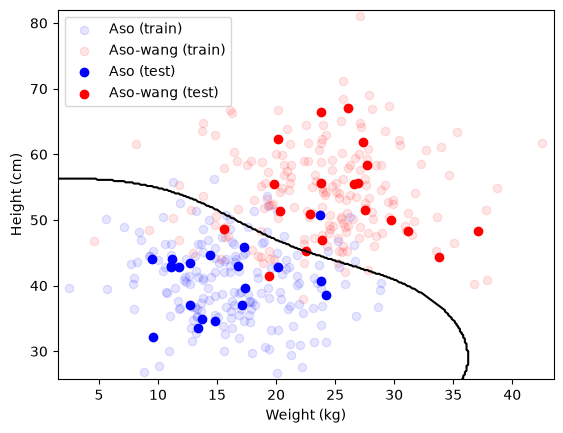

In [360]:
visualize_boundary_for_test(model, X_train, y_train, X_test, y_test)